<a href="https://colab.research.google.com/github/pr5952-creator/SVM-LINEAR-AND-NON-LINEAR/blob/main/SVM_LINEAR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving data_banknote_authentication.txt to data_banknote_authentication (1).txt
   variance  skewness  curtosis  entropy  class
0   3.62160    8.6661   -2.8073 -0.44699      0
1   4.54590    8.1674   -2.4586 -1.46210      0
2   3.86600   -2.6383    1.9242  0.10645      0
3   3.45660    9.5228   -4.0112 -3.59440      0
4   0.32924   -4.4552    4.5718 -0.98880      0

Missing values:
 variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64

Duplicate rows: 24

Accuracy: 0.9888888888888889
Precision: 0.976
Recall: 1.0
F1-score: 0.9878542510121457
ROC-AUC: 1.0

Classification Report:

              precision    recall  f1-score   support

           0       1.00      0.98      0.99       148
           1       0.98      1.00      0.99       122

    accuracy                           0.99       270
   macro avg       0.99      0.99      0.99       270
weighted avg       0.99      0.99      0.99       270



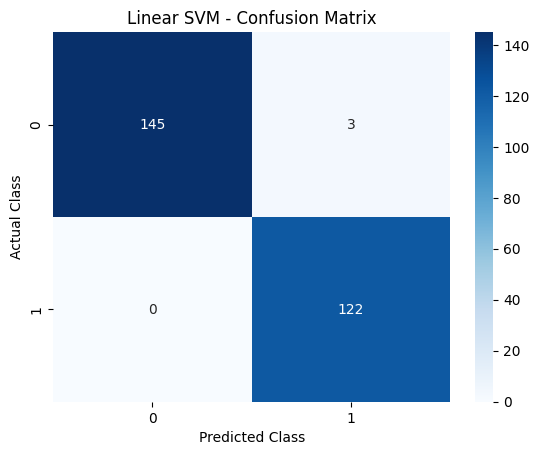

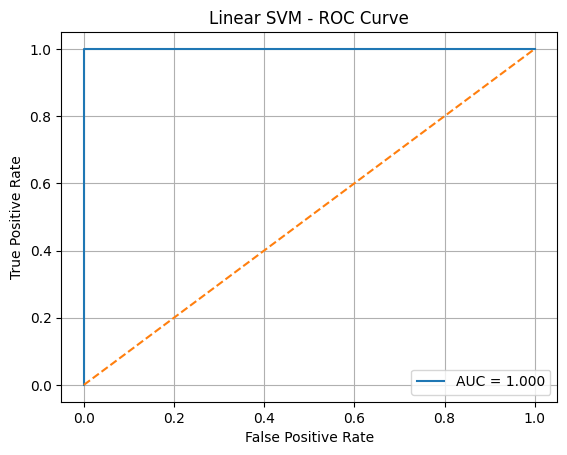

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    roc_auc_score, roc_curve
)

# 1. Load TXT dataset
uploaded = files.upload()
columns = ["variance", "skewness", "curtosis", "entropy", "class"]
df = pd.read_csv(next(iter(uploaded)),
                 header=None, names=columns)

# 2. Preprocessing
print(df.head())
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().dropna()

X = df.drop("class", axis=1)
y = df["class"].astype(int)

# 3. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Feature scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 5. Train Linear SVM
model = SVC(kernel="linear", C=1.0)
model.fit(X_train, y_train)

# 6. Prediction
y_pred = model.predict(X_test)
y_scores = model.decision_function(X_test)

# 7. Performance metrics
print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_scores))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, zero_division=0))

# 8. Confusion matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Linear SVM - Confusion Matrix")
plt.show()

# 9. ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_scores)
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, y_scores):.3f}")
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Linear SVM - ROC Curve")
plt.legend()
plt.grid()
plt.show()
